In [ ]:
# script for computing NN for a homogeneous half-space 
# for spherical cavities and single vertical point force
# In the end we also divide out the source spectra, since it is supposed to correspond to
# a single vertical force impulse response
import numpy as np
import os
from joblib import Parallel, delayed
import matplotlib.pyplot as plt
from scipy.io import savemat
from scipy.io import loadmat
from scipy.integrate import quad, tplquad, dblquad
import scipy.constants as const

from pysurf96 import surf96
from modules import configLoader
from modules import validateInputs
from modules import createDB
from modules import NNGeometryNN
from modules import gfLoader
from modules import simDisp
from modules import NNCompute


# load the config file
configFile="/home/koley/CavityResults/SphereValidTutorial/SingleForce/configParseHalfSpaceFullFieldHomo.ini"
config = configLoader.load_config(configFile)
# load all cavities
allCavities = configLoader.loadCavities('/home/koley/CavityResults/SphereValidTutorial/SingleForce/SingleSphCavityHalfSpace.ini')
validateInputs.validateInputs(config)
fullSpace = False
splitAll = createDB.createFinalInputs(config)

print(f"Prepared {splitAll.shape[0]} total runs")
print(f"Cores available: {config.cpuCoresQseis}")

results = createDB.runMultiQseis(splitAll, config.inputPath, config.qseisExe, nWorkers = config.cpuCoresQseis)
    
print("Database generation complete")
# flag for pure Rayleigh wavefield in homogeneous half-space
ifRay = config.ifRay
# flag for plane P and S waves in homogeneous half space
ifBody = config.ifBody
# flag for wavefield simulation
ifFullField = config.ifFullField
saveHV = config.saveHV
thickness = config.thickness # units in meters
vs = config.vS # units in m/s
vp = config.vP # units in m/s
rho = config.rho # units in kg/m^3
rhoAir = config.rhoAir # density of air
fMin = config.fMin; fMax = config.fMax; df = config.df;# units in Hz
lambdaFrac = config.lambdaFrac # fraction
lambdaRes = config.lambdaRes; #must be greater than 4
    
# given a cuboidal domain should be greater than sqrt of 
xMaxGF = config.xMaxGF # maximum horizontal offset upto which displacements will be used
zMaxGF = config.zMaxGF # maximum depth upto which displacements will be used
maxRec = config.maxRec # same value of number of receivers that qseis can handle in one go check qsglobal.h
xCenter = config.xCenter; yCenter = config.yCenter
xMin = xCenter-config.xExtent; xMax = xCenter+config.xExtent # minimum and maximum of the simulation domain in X-direction (EW)
yMin = yCenter-config.yExtent; yMax = yCenter+config.yExtent # maximum and minimum of the simulation domain in Y-direction (NS)
zMin = 0.0; zMax = config.zExtent # maximum and minimum of the simulation domain in Z-direction (depth)

# check if the GFs are generated up to correct hoizontal offsets
xDiag = (xMax-xMin)*np.sqrt(2); yDiag = (yMax-yMin)*np.sqrt(2);
if(xMaxGF<xDiag or xMaxGF<yDiag):
    raise ValueError("xMaxGF must be >= sqrt(2)x(xMax-xMin) and sqrt(2)x(yMax-yMin)")

if(zMaxGF<zMax):
    raise ValueError("zMaxGF must be greater >= zMax")
        
domXYBounds = (xMin,xMax,yMin,yMax)

# specify test-mass locations, this was originally defined after cubeTop cubeBot definition
itmAC = config.itmAC; itmAB = config.itmAB; etmCA = config.etmCA; etmBA = config.etmBA
    
print('itmAC = ' + str(itmAC[0]) + ', ' + str(itmAC[1]) + ', ' + str(itmAC[2]))
# make itmAC[2] negative, because in the configfile it is positive
itmACUse = itmAC.copy(); itmACUse[2] = -np.abs(itmACUse[2])
itmABUse = itmAB.copy(); itmABUse[2] = -np.abs(itmABUse[2])
etmCAUse = etmCA.copy(); etmCAUse[2] = -np.abs(etmCAUse[2])
etmBAUse = etmBA.copy(); etmBAUse[2] = -np.abs(etmBAUse[2])
    
itmAll = np.vstack((itmACUse,))
nTM = len(itmAll[:,0])
G = const.G

# an addition from the older version, where it is impoprtant to note that which cavity hosts
# which test-mass

# an addition from the older version, where it is important to note that which cavity hosts
# which test-mass

tmInCavity = NNGeometryNN.findTMInCavity(allCavities, itmAll)

# generate the grid size required
gridSize = NNCompute.getGridSize(thickness,vp, vs, rho, fMin, fMax, lambdaFrac, lambdaRes)
print('grid size in each layer before partitioning = ' + str(gridSize))

# get the background gridsize in the layer hosting the cavities
hBGAll = NNGeometryNN.getHBG(thickness,allCavities,gridSize)
etaUse = 0.5
radNow = allCavities[0]['radius']
# now get the refinement extent for all cavities
wallRefineWidthAll = NNGeometryNN.getRefineWidths(tmInCavity, allCavities, hBGAll,eta=etaUse,
                                                          minRefine=20.0,)
    
print('wallRefineWidth = ')
print(wallRefineWidthAll)

#refineBoxes = NNGeometryNN.makeRefineBoxesFromCavities(allCavities,wallRefineWidthAll)
refineBoxes = NNGeometryNN.makeRefineBoxesFromCavities(allCavities,wallRefineWidthAll,domainZBounds=(zMin,zMax))

cubeTopAll = np.zeros((len(allCavities),))
cubeBotAll = np.zeros((len(allCavities),))
for boxNo, box in enumerate(refineBoxes):
    cubeTopAll[boxNo] = box.zMin
    cubeBotAll[boxNo] = box.zMax
cubeTop = min(cubeTopAll)
cubeBot = max(cubeBotAll)
# new part added
    
cavDepthAll = np.zeros((len(allCavities),))
for cavNo, cav in enumerate(allCavities):    
    if(cav["shape"]=="cuboid"):
        cavDepthAll[cavNo] = cav["zC"]
    elif(cav["shape"] == 'sphere'):
        cavDepthAll[cavNo] = cav["zC"]
    else:
        ValueError('Unsupported cavity type')
cavDepthUse = min(cavDepthAll)

print("CubeTop = " + str(cubeTop) +  'CubeBot = ' + str(cubeBot))
    
# some other inputs for simDisp
maxRec = config.maxRec; # same value of number of receivers that qseis can handle in one go check qsglobal.h
tMax = config.tMax; nSamp = config.nSamp
    
# specify the folder where you want to write all input files, should have rw access
# fInpPath is the path where the Green's function database exists
fInpPath = config.inputPath #like "/data/gravwav/koley/QseisInpN/"
#fInpPath = "/data/gravwav/koley/SALVUSOut/"

# outDispPath should have rw access and is used for saving temp displacementy files
outDispPath = config.outDispPath # like "/data/gravwav/koley/OutDisp/"

# saves the NN and displacement values per realization
outDispRea = config.outDispPathRea # like "/data/gravwav/koley/OutDispRea/"
    
# GF components to be used
components = ['fh-2.tz', 'fh-2.tr', 'fh-2.tt', 'fz-2.tz', 'fz-2.tr']

# splitAll is necessary so load it
nRea = config.nRea # number of realizations

# this file is created at the time of database generation
splitFileName = fInpPath + 'splitAll.mat'
splitMat = loadmat(splitFileName)
splitAll = splitMat['splitAll']

# source distribution parameters
R1 = config.R1; R2 = config.R2
nSrc = config.nSrc
srcDistri = config.srcDistri
scaleVH = config.scaleVH
# flag if NN is computed directly without writing the displacemnet field
onFlyNN = config.onFlyNN 

# number of CPUs to be used for displacement and NN simulation
nCPUDisp = config.cpuCoresDisp
nCPUNN = config.cpuCoresNN
computeStrategy = config.computeStrategy

# frequency axis to be used by simDisp
freqOut, idxFreq, df_native = simDisp.getFreqGrid(tMax, nSamp, fMin, fMax, df)
dt = tMax/nSamp
nFreq = len(freqOut)
waveletF, tau = simDisp.qseisWaveletResponse(freqOut, tMax, nSamp,waveletDurationSamples=4.0)

splitAllNew = gfLoader.assembleQseisRuns(splitAll, fInpPath, components, outPath=None, fIndices=idxFreq, onlySplitAll = False, minVel=200.0)
#splitAllNew = np.load(os.path.join(fInpPath,'splitAllNew.npy'))

# in case only Rayleigh waves in homogeneous half space is used, Rayleigh wave phase velocity is needed
if(ifRay):
    periods = 1/freqOut
    vR = surf96(thickness,vp,vs,rho,periods,wave="rayleigh",mode=1,velocity="phase",flat_earth=True)
else:
    vR = None
# two depth points for scaling, displacement saved per realization
zList = [0.0,cavDepthUse-allCavities[0]['radius']]
    
# generate the grid size required
gridSize = NNCompute.getGridSize(thickness,vp, vs, rho, fMin, fMax, lambdaFrac, lambdaRes)
    
print('grid size in each layer before partitioning = ' + str(gridSize))
    
# create the layers and partition
layers, vp2, vs2, rho2, gridSize2 = NNGeometryNN.createAllLayers(xMin, xMax, yMin, yMax, thickness,
                                                                 zMax,vp,vs,rho,gridSize,cubeTop,cubeBot,
                                                                 maxHostThickness=np.ceil(cubeBot-cubeTop))
print('New gridSize after partioning = '+ str(gridSize2))

print('Total number of layers = ' + str(len(layers)))
nLayers = len(layers)
    
for reaNo in range(0,nRea):
    print('Doing realization = ' +str(reaNo))
    # get the source distribution per realization
    xSrc, ySrc, azSrc, srcMeta =  simDisp.genAmbSrc(nSrc , mode = srcDistri, R1 = R1, R2 = R2, xMin=xMin, xMax=xMax, yMin=yMin,
                                        yMax=yMax, randomPhase=True, freqDependent=True, nFreq=nFreq, decoupledHV=config.decoupledHV,
                                        scaleVH = scaleVH)
    # change source parameters corresponding to a single vertical force impulse response
    xSrc[0] = -2000.0; ySrc[0] = 0.0; azSrc[0] = np.pi/2
    srcMeta["ampV"][:] = 1.0; srcMeta["phiV"][:] = 0.0
    srcMeta["ampH"] *= 0.0; srcMeta['phiH'] *= 0.0
    # in case the body wave in homogeneous half-space flag is turned on
    if(ifBody):
        metaBody = simDisp.genBodySrc(nSrc, nFreq, eP = 0.1, eS = 0.9)
    else:
        metaBody=None
        
    # create and save the displacement field on surface and depth for scaling afterwards
    if(ifRay):
        # uses ambient Rayleigh wavefield in homogeneous half space
        phiSrc = srcMeta["phiV"]; ampSrc = srcMeta["ampV"]
        simDisp.getSurfDeepRayDispPerRea(zList, azSrc, phiSrc, ampSrc, outDispRea, reaNo, vR,
                                        vp2[0], vs2[0], freqOut=freqOut)
    elif(ifBody):
        # uses Plane P and S wave in homogeneous half space
        simDisp.getSurfDeepBodyDispPerRea(zList, metaBody, outDispRea, reaNo, vp2[0], vs2[0], freqOut=freqOut)
        
    else:
        # uses QSEIS full wavefield simulation instead
        simDisp.getSurfDeepDispPerRea(zList, xSrc, ySrc, azSrc, srcMeta, xMaxGF, splitAll, fMin, fMax, outDispRea,
                    fInpPath, components, reaNo, idxFreq = idxFreq, freqOut=freqOut)
        
    # preallocate per realization
    IBlockTot = np.zeros((nFreq,3,nTM),dtype=np.complex128)
    IVertFaceTot  = np.zeros((nFreq,3,nTM),dtype=np.complex128)
    IHorFaceTot = np.zeros((nFreq,3,nTM),dtype=np.complex128)
    ITot = np.zeros((nFreq,3,nTM),dtype=np.complex128)
        
    for layerNo, layer in enumerate(layers):
        layer = layers[layerNo]

        # need to redefine cubeTop and cubeBot for multiple cavities
        layer.updateCubeInteraction(cubeTop, cubeBot)
        #layer.generateBlocks(xMin, xMax, yMin, yMax, cubeC, ax, ay, az, domXYBounds)
        layer.generateBlocksNew(refineBoxes=refineBoxes,domXYBounds=domXYBounds,
                                domainZBounds=(zMin, zMax))
            
        print(layer)
        blkNo = 1
        for blk in layer.blocks:
            print(blk);
            print('Block = '+str(blkNo))
            print('Integrating volume  NN block in layer' + str(layerNo))

            # new version signature
            IBlock = NNCompute.runVolNNComputeBlock(blk, gridSize2[layerNo], freqOut, allCavities, itmAll,
                                                    xSrc, ySrc, azSrc,srcMeta, idxFreq, fMin, fMax, outDispPath, splitAll, xMaxGF,
                                                    fInpPath, components, vR, useSimDisp=ifFullField, ifRay = ifRay, ifBody = ifBody,
                                                    nCPUDisp=nCPUDisp, nCPUNN=nCPUNN, nChunk=20000,metaBody=metaBody,
                                                    computeStrategy=computeStrategy,saveHV=saveHV)
            # new version
            IBlockTot = IBlockTot + IBlock

            # now compute the surface NN from the vertical faces of the block which form the outer boundary
            for f in blk.verticalFaces:
                if(f.isBoundary):
                    print('Integrating vertical surface NN block in layer' + str(layerNo))
                    print('vertical boundary face found')
                    # is an outer boundary
                    IVertFace = NNCompute.runVertSurfNNCompute(f, gridSize2[layerNo], freqOut, itmAll, xSrc, ySrc, azSrc,
                                                    srcMeta, idxFreq, fMin, fMax, outDispPath, splitAllNew,
                                                    xMaxGF, fInpPath, components, vR, nCPUDisp=1, nChunk = 20000, 
                                                    useSimDisp=ifFullField, ifRay = ifRay, ifBody = ifBody, vP_for_test=blk.vP,
                                                    vS_for_test=blk.vS, metaBody=metaBody,
                                                    computeStrategy=computeStrategy,saveHV=saveHV, reduceNN=onFlyNN)
                        
                    IVertFaceTot = IVertFaceTot + IVertFace
        
                
            # now compute the surface NN from the horizontal interfaces at the very end of layers
            print('Integrating horizontal surface NN block in layer' + str(layerNo))
            IHorFace = NNCompute.handleHorSurfNN(layer, layers, blk, gridSize2[layerNo], nLayers, layerNo, rhoAir, freqOut, 
                                        allCavities, itmAll, xSrc, ySrc, azSrc, srcMeta, idxFreq, fMin, fMax, outDispPath,
                                        splitAllNew, xMaxGF, fInpPath, components, vR, nCPUDisp=nCPUDisp,
                                        nCPUNN=nCPUNN, useSimDisp = ifFullField, ifRay = ifRay, ifBody = ifBody,
                                        vP_for_test=blk.vP, vS_for_test = blk.vS, metaBody = metaBody, chunk_size=20000,
                                        computeStrategy=computeStrategy, saveHV=saveHV, reduceNN=onFlyNN,fullSpace=fullSpace)
                                
            IHorFaceTot = IHorFaceTot + IHorFace
                
            blkNo = blkNo+1
    
    IVertFaceTot = IVertFaceTot*G
    IHorFaceTot = IHorFaceTot*G
    IBlockTot = IBlockTot*G
    ITot = (IBlockTot-IVertFaceTot-IHorFaceTot)
    # save the NN per realization
    nnFName = 'NNFullRea' + str(reaNo) + '.npz'
    np.savez(os.path.join(outDispRea, nnFName), IVertFaceTot = IVertFaceTot, IHorFaceTot = IHorFaceTot,
            IBlockTot = IBlockTot, ITot = ITot, freqOut=freqOut)

dispPointAllRea, attnAllRea, freqDisp = simDisp.assembleSurfDeepDispAllRea(outDispRea, zList, freqOut, nRea)
nnAllRea, nnVolAllRea, nnSurfAllRea, fNN = NNCompute.assembleNNAllReaAllTM(outDispRea,freqOut, nRea,nTM)

# do the decon with the source wavelet, which is almost delta-like
Wnn = np.abs(waveletF[:, None, None]) # (nFreq, 1, 1)
deconDisp = dispPointAllRea/Wnn*dt
deconFullNN = nnAllRea/Wnn*dt
deconVolNN = nnVolAllRea/Wnn*dt
deconSurfNN = nnSurfAllRea/Wnn*dt

All configuration and model checks passed.
Layer depths = [   0. 4000.]
Number of points per layer along Z = [102]
Spacing in each layer in meters = [39.06807669 42.19409283]
Qseis Inputs cleaned, parent folder intact.
Creating all input files ...
All input files created!
Prepared 515 total runs
Cores available: 64
Preparing to run 515 QSEIS jobs with 64 worker(s)...


/home/koley/.conda/envs/pySeis1DNN/lib/python3.11/site-packages/pysurf96/wrapper.py:99: RuntimeWarning: overflow encountered in cast
  error = surfdisp96(


[Worker 2715526] Starting job Layer0Run0 at 12:13:22[Worker 2715528] Starting job Layer0Run2 at 12:13:22[Worker 2715527] Starting job Layer0Run1 at 12:13:22[Worker 2715529] Starting job Layer0Run3 at 12:13:22[Worker 2715531] Starting job Layer1Run0 at 12:13:22[Worker 2715530] Starting job Layer0Run4 at 12:13:22[Worker 2715532] Starting job Layer1Run1 at 12:13:22
[Worker 2715533] Starting job Layer1Run2 at 12:13:22[Worker 2715534] Starting job Layer1Run3 at 12:13:22[Worker 2715535] Starting job Layer1Run4 at 12:13:22[Worker 2715537] Starting job Layer2Run1 at 12:13:22[Worker 2715536] Starting job Layer2Run0 at 12:13:22
[Worker 2715538] Starting job Layer2Run2 at 12:13:22[Worker 2715540] Starting job Layer2Run4 at 12:13:22[Worker 2715539] Starting job Layer2Run3 at 12:13:22[Worker 2715542] Starting job Layer3Run1 at 12:13:22[Worker 2715541] Starting job Layer3Run0 at 12:13:22[Worker 2715543] Starting job Layer3Run2 at 12:13:22
[Worker 2715544] Starting job Layer3Run3 at 12:13:22

[Worker

In [17]:
# update plotting parameters
import matplotlib.pyplot as plt
plt.rcParams.update({
    'figure.titlesize': 18,     # Overall figure suptitle size
    'axes.titlesize': 16,       # Subplot title size
    'axes.labelsize': 16,       # X and Y axis labels (e.g. "Frequency (Hz)")
    'xtick.labelsize': 16,      # X-axis tick numbers/values
    'ytick.labelsize': 16,      # Y-axis tick numbers/values
    'legend.fontsize': 14,      # Legend text size
})

[0.    0.025 0.05  0.075 0.1  ]


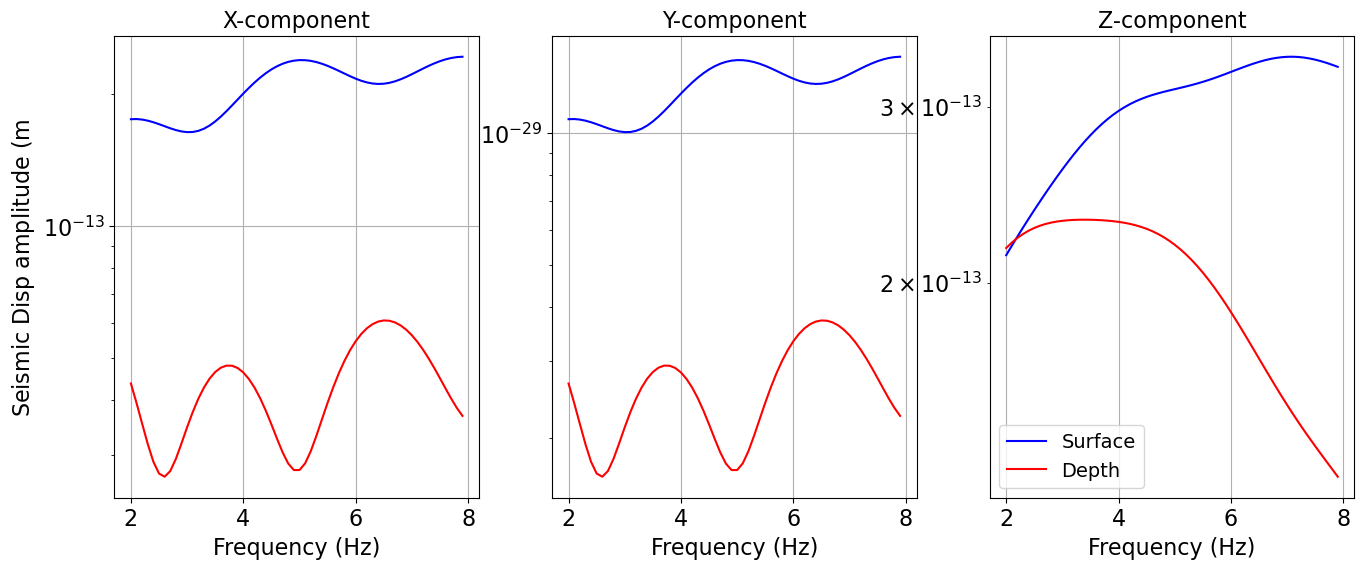

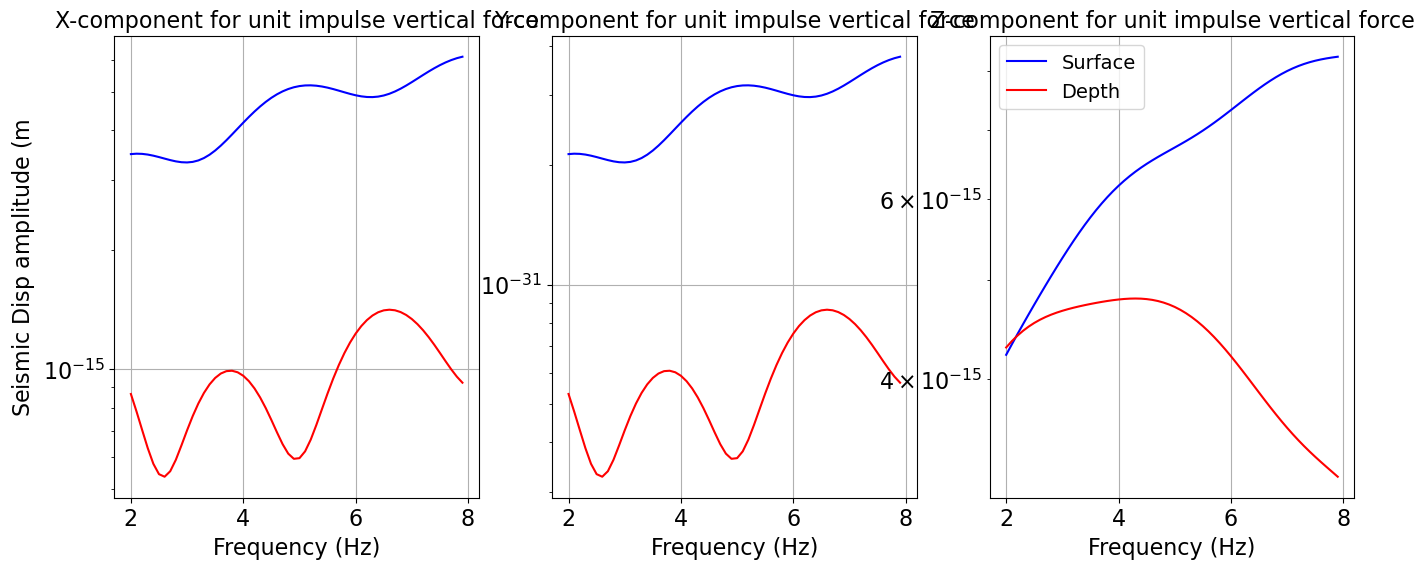

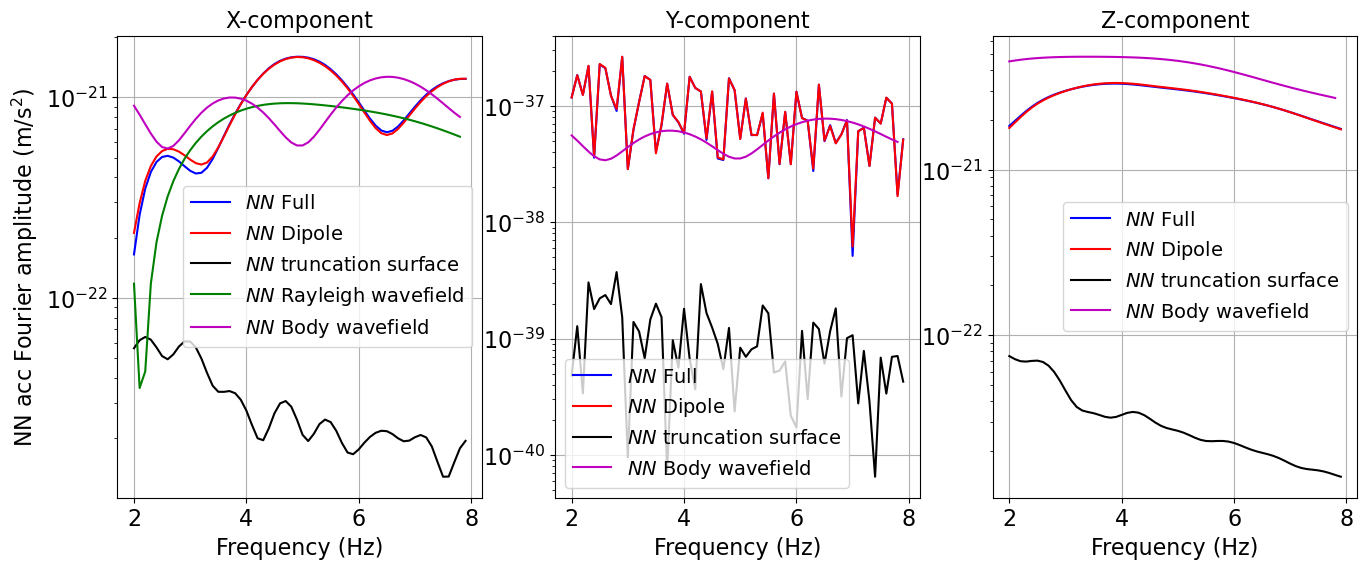

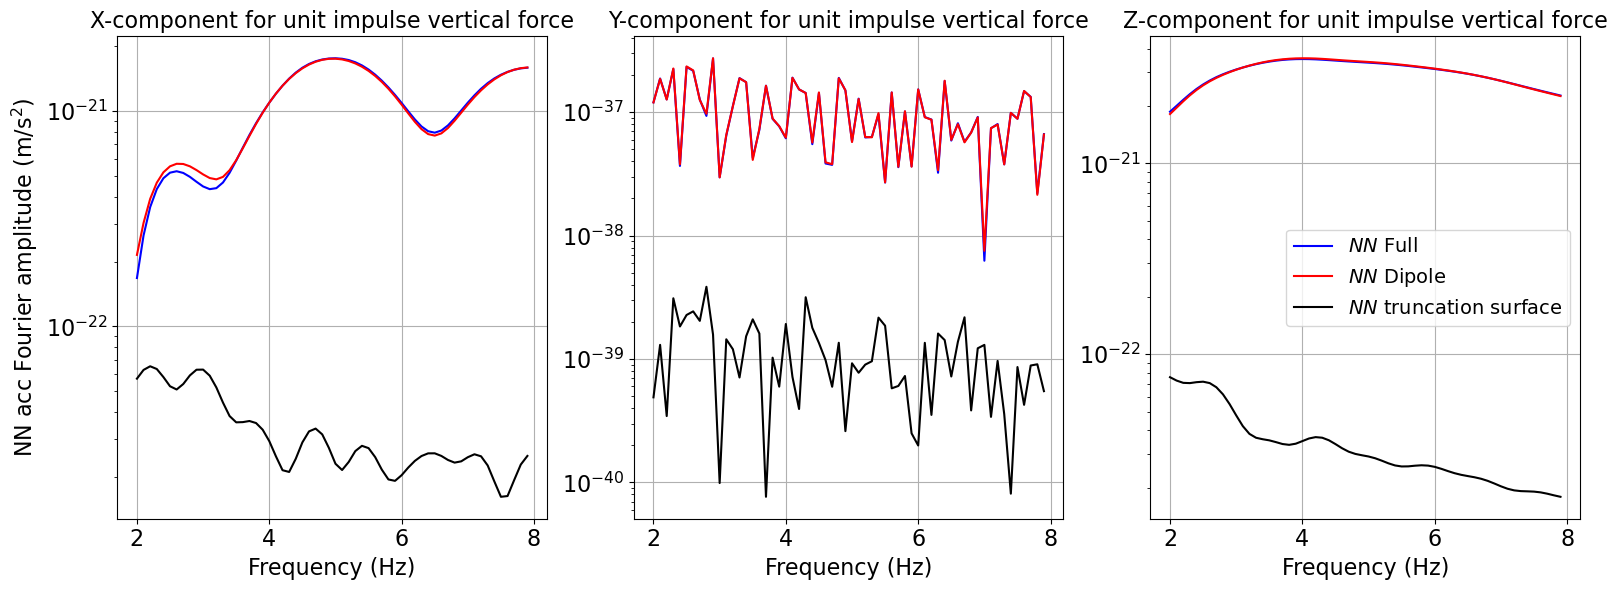

In [18]:
import numpy as np
import matplotlib.pyplot as plt

from pysurf96 import surf96
from modules import configLoader
from modules import simDisp
from modules import NNCompute
# if the previous cell was not run in the same session, and outputs
# were saved then reload the results
freshLaunch = 1; # or 0 if continued from previous cell
if(freshLaunch):
    # load the config file
    configFile="/home/koley/CavityResults/SphereValidTutorial/SingleForce/configParseHalfSpaceFullFieldHomo.ini"
    config = configLoader.load_config(configFile)
    
    allCavities = configLoader.loadCavities('/home/koley/CavityResults/SphereValidTutorial/SingleForce/SingleSphCavityHalfSpace.ini')

    outDispRea = config.outDispPathRea
    nRea = config.nRea
    nTM = 1
    tMax = config.tMax; nSamp = config.nSamp; fMin = config.fMin
    fMax = config.fMax; df = config.df
    freqOut, idxFreq, df_native = simDisp.getFreqGrid(tMax, nSamp, fMin, fMax, df)
    dt = tMax/nSamp

    cavDepthAll = np.zeros((len(allCavities),))
    for cavNo, cav in enumerate(allCavities):    
        if(cav["shape"]=="cuboid"):
            cavDepthAll[cavNo] = cav["zC"]
        elif(cav["shape"] == 'sphere'):
            cavDepthAll[cavNo] = cav["zC"]
        else:
            ValueError('Unsupported cavity type')
    cavDepthUse = min(cavDepthAll)
    zList = [0.0,cavDepthUse-allCavities[0]['radius']]

    waveletF, tau = simDisp.qseisWaveletResponse(freqOut, tMax, nSamp,waveletDurationSamples=4.0)
    dispPointAllRea, attnAllRea, freqDisp = simDisp.assembleSurfDeepDispAllRea(outDispRea, zList, freqOut, nRea)
    nnAllRea, nnVolAllRea, nnSurfAllRea, fNN = NNCompute.assembleNNAllReaAllTM(outDispRea,freqOut, nRea,nTM)

    # do the decon with the source wavelet, which is almost delta-like
    Wnn = np.abs(waveletF[:, None, None]) # (nFreq, 1, 1)
    deconDisp = dispPointAllRea/Wnn*dt
    deconFullNN = nnAllRea/Wnn*dt
    deconVolNN = nnVolAllRea/Wnn*dt
    deconSurfNN = nnSurfAllRea/Wnn*dt

# get the Rayleigh and body wave NN just for comparison
NNRay,freqNNRay = NNCompute.getAnalyticRayNN(config, cavDepthUse)
# now multiply it with the surface Z disp ASD
NNRay = NNRay*np.abs(dispPointAllRea[0:59,2,0])*dt

NNBody, minNN, freqNNBody = NNCompute.getAnalyticBodyNN(config,p=1/3)

NNBody = NNBody[:,None]*np.abs(dispPointAllRea[0:59,:,1])*dt

fig0,ax0 = plt.subplots(1,3,figsize=(16,6))
for i in range(0,3):
    ax0[i].semilogy(freqOut,dispPointAllRea[:,i,0],'b',label=r"Surface")
    ax0[i].semilogy(freqOut,dispPointAllRea[:,i,1],'r',label=r"Depth")
    ax0[i].set_xlabel('Frequency (Hz)')
    if(i==0):
        ax0[i].set_ylabel(r"Seismic Disp amplitude $\mathrm{(m}$")
    ax0[i].set_title(f'{["X","Y","Z"][i]}-component')
    ax0[i].grid()
    if(i==2):
        ax0[i].legend()

fig1,ax1 = plt.subplots(1,3,figsize=(16,6))
for i in range(0,3):
    ax1[i].semilogy(freqOut,deconDisp[:,i,0],'b',label=r"Surface")
    ax1[i].semilogy(freqOut,deconDisp[:,i,1],'r',label=r"Depth")
    ax1[i].set_xlabel('Frequency (Hz)')
    if(i==0):
        ax1[i].set_ylabel(r"Seismic Disp amplitude $\mathrm{(m}$")
    ax1[i].set_title(f'{["X","Y","Z"][i]}-component for unit impulse vertical force')
    ax1[i].grid()
    if(i==2):
        ax1[i].legend()

fig2,ax2 = plt.subplots(1,3,figsize=(16,6))
for i in range(0,3):
    ax2[i].semilogy(freqOut,nnAllRea[:,i,0]*dt,'b',label=r"$NN$ Full")
    ax2[i].semilogy(freqOut,nnVolAllRea[:,i,0]*dt,'r',label=r"$NN$ Dipole")
    ax2[i].semilogy(freqOut,nnSurfAllRea[:,i,0]*dt,'k',label=r"$NN$ truncation surface")
    if(i==0):
        ax2[i].semilogy(freqNNRay, NNRay,'g',label=r"$NN$ Rayleigh wavefield")
    ax2[i].semilogy(freqNNBody, NNBody[:,i],'m',label=r"$NN$ Body wavefield")
    ax2[i].set_xlabel('Frequency (Hz)')
    if(i==0):
        ax2[i].set_ylabel(r"NN acc Fourier amplitude $\mathrm{(m}/\mathrm{s}^2\mathrm{)}$")
    ax2[i].set_title(f'{["X","Y","Z"][i]}-component')
    ax2[i].grid()
    ax2[i].legend()

fig3,ax3 = plt.subplots(1,3,figsize=(16,6))
for i in range(0,3):
    ax3[i].semilogy(freqOut,deconFullNN[:,i,0],'b',label=r"$NN$ Full")
    ax3[i].semilogy(freqOut,deconVolNN[:,i,0],'r',label=r"$NN$ Dipole")
    ax3[i].semilogy(freqOut,deconSurfNN[:,i,0],'k',label=r"$NN$ truncation surface")
    ax3[i].set_xlabel('Frequency (Hz)')
    if(i==0):
        ax3[i].set_ylabel(r"NN acc Fourier amplitude $\mathrm{(m}/\mathrm{s}^2\mathrm{)}$")
    ax3[i].set_title(f'{["X","Y","Z"][i]}-component for unit impulse vertical force')
    ax3[i].grid()
    if(i==2):
        ax3[i].legend()

plt.tight_layout()


SPECFEM gravity:
  N        = 400
  dt       = 0.020000000000000018
  t range  = 0.02 to 8.0 s

SPECFEM source:
  STF source-time peak = 2.77555756e-17
  STF solver-time peak = 0.24005006499999948
  first gravity time   = 0.02

Minimum |Wspec| in 2-8 Hz = 1.7013095003205734


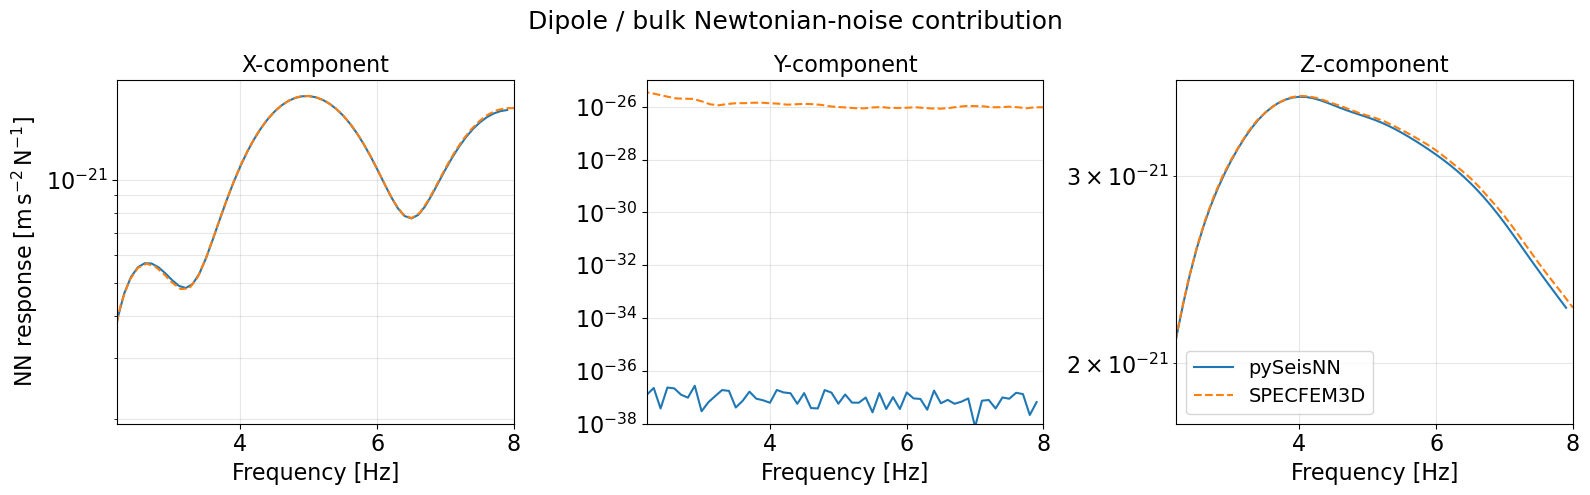

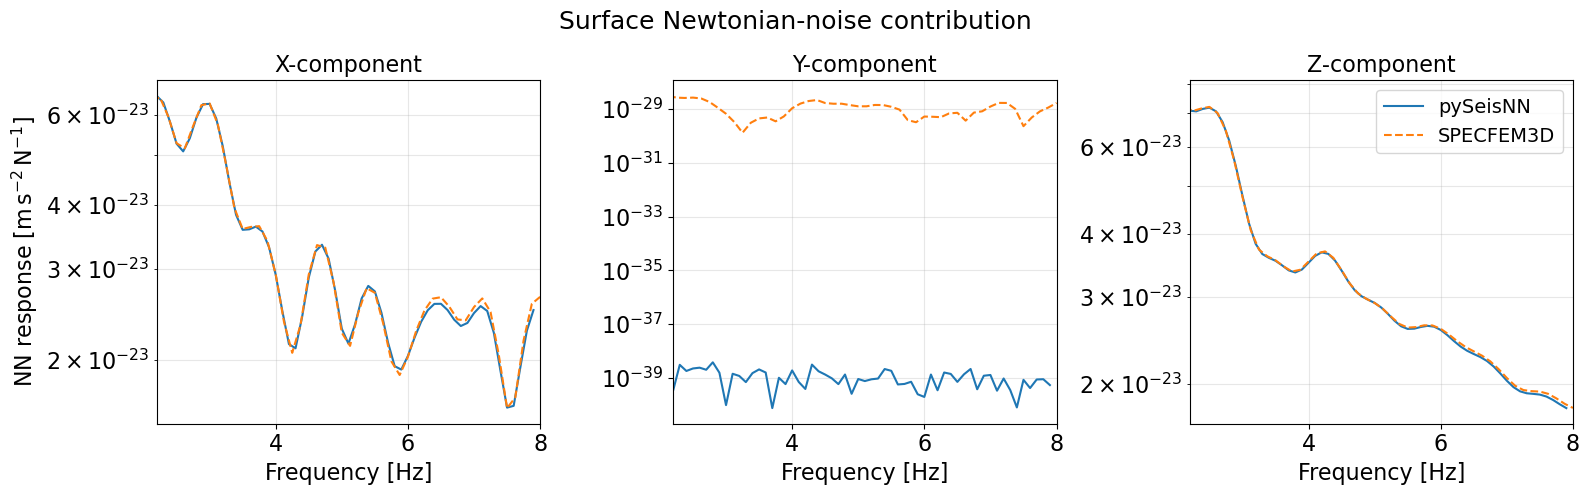

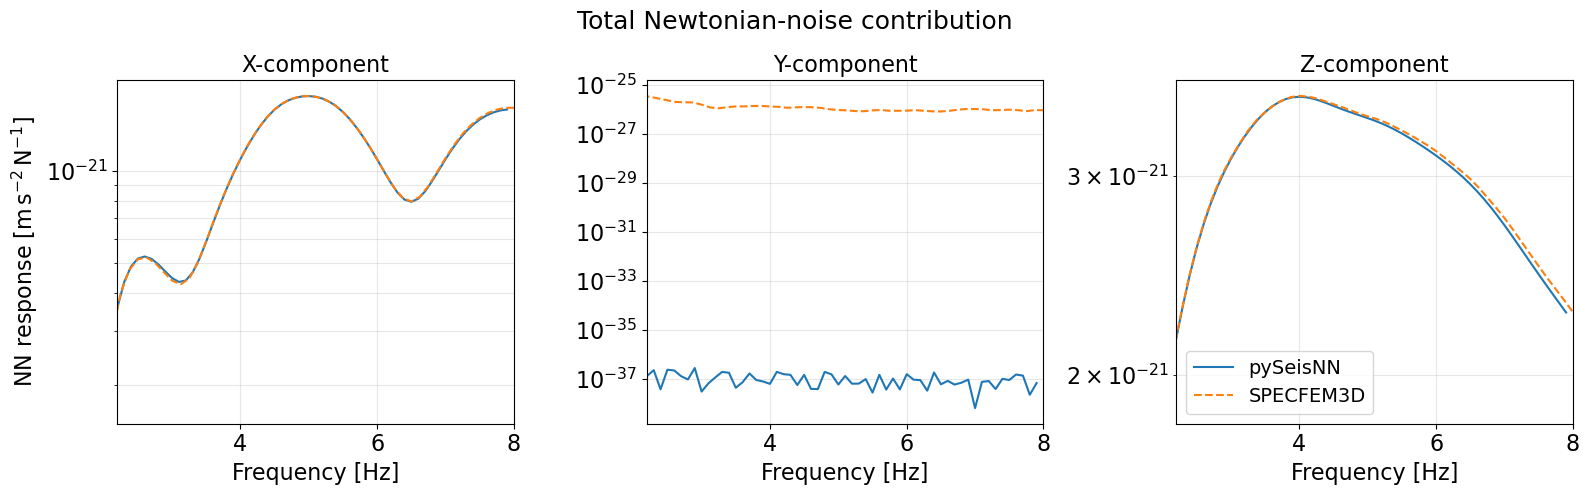

In [34]:
# ============================================================
# Compare deconvolved pySeisNN and SPECFEM3D NN
#
# pySeisNN:
#   deconVolNN   -> dipole / bulk contribution
#   deconSurfNN  -> truncation surface contribution
#   deconFullNN  -> total NN
#
# SPECFEM:
#   stat1.grav       -> bulk / dipole contribution
#   stat1.surf.grav  -> outer-surface contribution
#
# SPECFEM source:
#   F(t) = F0 * Ricker(t)
#   F0 = 1 N
#
# Therefore:
#   H_NN(f) = A_NN(f) / [F0 * W_Ricker(f)]
#
# Units:
#   m s^-2 N^-1
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import os
from scipy.interpolate import interp1d

# ============================================================
# 1. User settings
# ============================================================

SPEC_OUTPUT = "/home/koley/specfemRuns/HomoSphereNNSolid/OUTPUT_FILES"

# the dipole bulk contribution
grav_fileBulk = os.path.join(SPEC_OUTPUT,"stat1.grav")

# the truncation outer surface term contribution, modified specfem3d version
# check my github repo for the modified version of specfem3d
grav_fileSurf = os.path.join(SPEC_OUTPUT,"stat1.surf.grav")

# the source-time function used in the SPECFEM3D simulation, which is a Ricker wavelet
SPEC_STF_FILE = os.path.join(SPEC_OUTPUT,"plot_source_time_function.txt")

# SPECFEM force amplitude
F0 = 1.0       # N

# Frequency range for comparison
fMinComp = 2.0
fMaxComp = 8.0

compNames = ["X", "Y", "Z"]

# ============================================================
# 2. Read SPECFEM gravity outputs
# ============================================================

dataBulk = np.loadtxt(grav_fileBulk)
dataSurf = np.loadtxt(grav_fileSurf)

# Columns:
# time, accE, accN, accZ

tBulk = dataBulk[:, 0]
accBulk = np.column_stack([dataBulk[:, 1],dataBulk[:, 2],dataBulk[:, 3]])
tSurf = dataSurf[:, 0]
accSurf = np.column_stack([dataSurf[:, 1],dataSurf[:, 2],dataSurf[:, 3]])

# ============================================================
# 3. Remove non-finite samples
# ============================================================
# a safeguard, not always necessary, but better to be safe than sorry
finiteBulk = (np.isfinite(tBulk)& np.all(np.isfinite(accBulk), axis=1))
finiteSurf = (np.isfinite(tSurf)& np.all(np.isfinite(accSurf), axis=1))
tBulk = tBulk[finiteBulk]
accBulk = accBulk[finiteBulk, :]
tSurf = tSurf[finiteSurf]
accSurf = accSurf[finiteSurf, :]

# ============================================================
# 4. Check that bulk and surface use identical time grid
# ============================================================
dtBulk = np.median(np.diff(tBulk))
dtSurf = np.median(np.diff(tSurf))

if not np.isclose(dtBulk, dtSurf):
    raise ValueError("Bulk and surface gravity outputs have different dt.")

if len(tBulk) != len(tSurf):
    raise ValueError("Bulk and surface gravity outputs have different lengths.")

if not np.allclose(tBulk, tSurf):
    raise ValueError("Bulk and surface gravity time vectors differ.")

tGrav = tBulk
dtGrav = dtBulk

print("SPECFEM gravity:")
print("  N        =", len(tGrav))
print("  dt       =", dtGrav)
print("  t range  =", tGrav[0], "to", tGrav[-1], "s")

# ============================================================
# 5. Load actual SPECFEM Ricker STF
# ============================================================

stfSpecData = np.loadtxt(SPEC_STF_FILE)
tStfSpec = stfSpecData[:, 0]
stfSpec = stfSpecData[:, 1]
dtStfSpec = np.median(np.diff(tStfSpec))
iPeak = np.argmax(np.abs(stfSpec))
# actually the ricker here is zero-phase wavelet

# ============================================================
# 6. Convert SPECFEM source-time coordinate
#    to solver-time coordinate
# ============================================================
#
# Source file:
#
#   source-time peak = 0
#
# Solver clock:
#
#   first STF sample corresponds approximately to one DT.
#
# ============================================================

tStfSolver = (tStfSpec- tStfSpec[0]+ dtStfSpec)
print("\nSPECFEM source:")
print("  STF source-time peak =",tStfSpec[iPeak])
print("  STF solver-time peak =",tStfSolver[iPeak])
print("  first gravity time   =",tGrav[0])

# ============================================================
# 7. Interpolate STF onto the gravity-output time grid
# ============================================================
# necessary because the specfem simulation runs on a much finer time-grid, whereas
# gravity is output at a much coarser time-grid, about 50 Hz
stfInterp = interp1d(tStfSolver,stfSpec,kind="cubic",bounds_error=False,fill_value=0.0)
stfOnGrav = stfInterp(tGrav)

# ============================================================
# 8. FFT of STF and gravity
# ============================================================
#
# IMPORTANT:
#
# gravity and STF now have:
#
#   same dt
#   same N
#   same time grid
#
# Therefore the dt factors cancel in the deconvolution.
# ============================================================

Nspec = len(tGrav)

freqSpec = np.fft.rfftfreq(Nspec,d=dtGrav)
# Source FFT
Wspec = np.fft.rfft(stfOnGrav)

# Gravity FFT
#
# axis=0 because shape is:
#
#   (time, component)

ABulk = np.fft.rfft(accBulk,axis=0)
ASurf = np.fft.rfft(accSurf, axis=0)

# ============================================================
# 9. Complex source deconvolution
# ============================================================
#
# A(f) = H(f) F0 W(f)
#
# therefore
#
# H(f) = A(f) / [F0 W(f)]
#
# Keep quantities COMPLEX here.
# ============================================================

HSpecBulk = (ABulk/(F0 * Wspec[:, None]))
HSpecSurf = (ASurf/(F0 * Wspec[:, None]))

# ============================================================
# 10. SPECFEM total NN
# ============================================================
#
# Add COMPLEX contributions first.
#
# Do not do:
#
# abs(HBulk) + abs(HSurf)
#
# ============================================================

HSpecTotal = (HSpecBulk-HSpecSurf)

# ============================================================
# 11. Frequency masks
# ============================================================
# spedfem3d
selSpec = ((freqSpec >= fMinComp)&(freqSpec <= fMaxComp))
# pySeisNN
selPy = ((freqOut >= fMinComp)&(freqOut <= fMaxComp))

# ============================================================
# Optional sanity check:
# source spectrum should not be close to zero in 2-8 Hz
# ============================================================
print("\nMinimum |Wspec| in 2-8 Hz =",np.min(np.abs(Wspec[selSpec])))

# ============================================================
# 12. Figure 1:
#     Dipole / bulk NN
# ============================================================

figDip, axDip = plt.subplots(1,3,figsize=(16, 5),sharey=False)
for i in range(3):
    # pySeisNN
    axDip[i].semilogy(freqOut[selPy],np.abs(deconVolNN[selPy, i, 0]),label="pySeisNN")
    # SPECFEM
    axDip[i].semilogy(freqSpec[selSpec],np.abs(HSpecBulk[selSpec, i]),"--",label="SPECFEM3D")
    axDip[i].set_xlabel("Frequency [Hz]")
    axDip[i].set_xlim(2.2,8.0)
    axDip[i].set_title(f"{compNames[i]}-component")
    axDip[i].grid(True,which="both",alpha=0.3)
    if i == 0:
        axDip[i].set_ylabel(r"NN response "r"$[\mathrm{m\,s^{-2}\,N^{-1}}]$")

    if i == 1:
        axDip[i].set_ylim(10**-38, 10**-25)

    if i == 2:
        axDip[i].legend()


figDip.suptitle("Dipole / bulk Newtonian-noise contribution")
plt.tight_layout()
plt.show()

# ============================================================
# 13. Figure 2:
#     Surface NN
# ============================================================

figSurf, axSurf = plt.subplots(1,3,figsize=(16, 5),sharey=False)
for i in range(3):

    # pySeisNN
    axSurf[i].semilogy(freqOut[selPy],np.abs(deconSurfNN[selPy, i, 0]),label="pySeisNN")
    # SPECFEM
    axSurf[i].semilogy(freqSpec[selSpec],np.abs(HSpecSurf[selSpec, i]),"--",label="SPECFEM3D")
    axSurf[i].set_xlabel("Frequency [Hz]")
    axSurf[i].set_xlim(2.2,8.0)
    axSurf[i].set_title(f"{compNames[i]}-component")
    axSurf[i].grid(True,which="both",alpha=0.3)
    if i == 0:
        axSurf[i].set_ylabel(r"NN response "r"$[\mathrm{m\,s^{-2}\,N^{-1}}]$")
    if i == 2:
        axSurf[i].legend()

figSurf.suptitle("Surface Newtonian-noise contribution")
plt.tight_layout()
plt.show()

# ============================================================
# 14. Figure 3:
#     Total NN
# ============================================================

figTot, axTot = plt.subplots(1,3,figsize=(16, 5),sharey=False)
for i in range(3):
    # pySeisNN
    axTot[i].semilogy(freqOut[selPy],np.abs(deconFullNN[selPy, i, 0]),label="pySeisNN")
    # SPECFEM
    axTot[i].semilogy(freqSpec[selSpec],np.abs(HSpecTotal[selSpec, i]),"--",label="SPECFEM3D")
    axTot[i].set_xlabel("Frequency [Hz]")
    axTot[i].set_xlim(2.2,8.0)
    axTot[i].set_title(f"{compNames[i]}-component")
    axTot[i].grid(True,which="both",alpha=0.3)

    if i == 0:
        axTot[i].set_ylabel(r"NN response "r"$[\mathrm{m\,s^{-2}\,N^{-1}}]$")
    if i == 2:
        axTot[i].legend()

figTot.suptitle("Total Newtonian-noise contribution")

plt.tight_layout()
plt.show()

Late X offset = -1.0458291508374996e-27
Late Z offset = 1.4863902457587496e-27


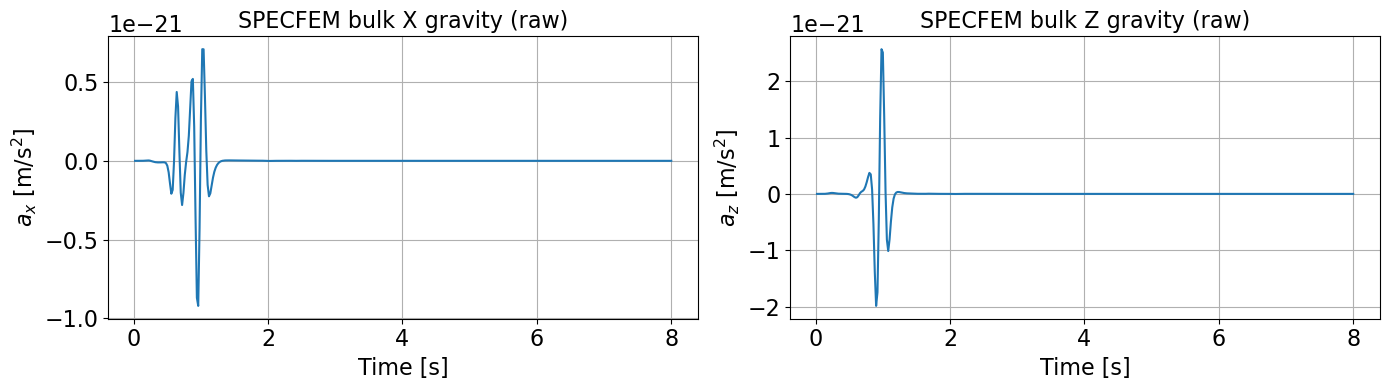

In [35]:
fig, ax = plt.subplots(1, 2, figsize=(14,4))

ax[0].plot(tGrav, accBulk[:,0])
ax[0].set_xlabel("Time [s]")
ax[0].set_ylabel(r"$a_x$ [m/s$^2$]")
ax[0].set_title("SPECFEM bulk X gravity (raw)")
ax[0].grid()

ax[1].plot(tGrav, accBulk[:,2])
ax[1].set_xlabel("Time [s]")
ax[1].set_ylabel(r"$a_z$ [m/s$^2$]")
ax[1].set_title("SPECFEM bulk Z gravity (raw)")
ax[1].grid()

plt.tight_layout()

nLate = int(0.2 * len(accBulk))

offsetX = np.mean(accBulk[-nLate:, 0])
offsetZ = np.mean(accBulk[-nLate:, 2])

print("Late X offset =", offsetX)
print("Late Z offset =", offsetZ)

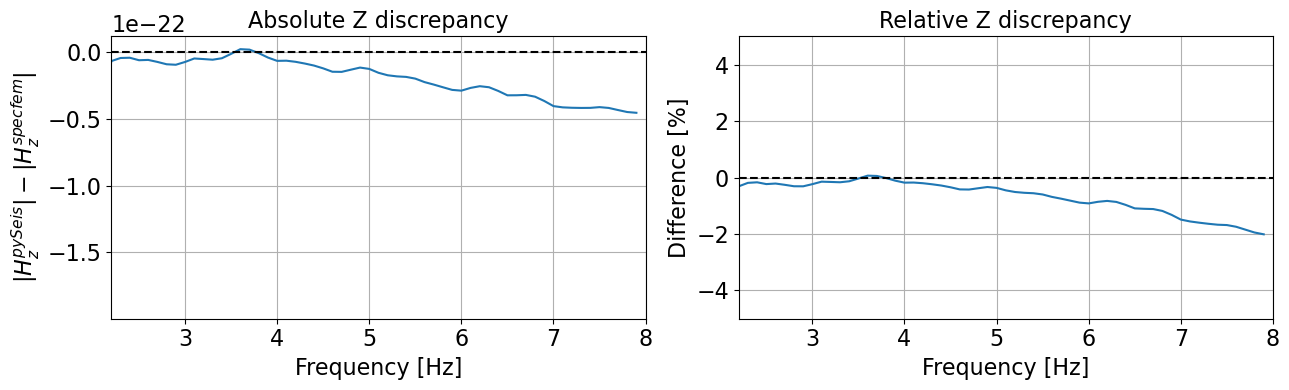

In [30]:
# interpolate SPECFEM magnitude onto pySeisNN frequency grid
# Z component comparison, since Y is ideally close to 0 for both
specZ_interp = np.interp(freqOut[selPy],freqSpec[selSpec],np.abs(HSpecBulk[selSpec, 2]))
pyZ = np.abs(deconVolNN[selPy, 2, 0])
diffZ = pyZ - specZ_interp
fig, ax = plt.subplots(1, 2,figsize=(13, 4))

ax[0].plot(freqOut[selPy],diffZ)
ax[0].axhline(0.0,color="k",linestyle="--")
ax[0].set_xlabel("Frequency [Hz]")
ax[0].set_ylabel(r"$|H_z^{pySeis}|-|H_z^{specfem}|$")
ax[0].set_title("Absolute Z discrepancy")
ax[0].grid()
ax[0].set_xlim(2.2,8.0)

ax[1].plot(freqOut[selPy],diffZ / pyZ * 100.0)
ax[1].axhline(0.0,color="k",linestyle="--")

ax[1].set_xlabel("Frequency [Hz]")
ax[1].set_ylabel("Difference [%]")
ax[1].set_title("Relative Z discrepancy")
ax[1].grid()
ax[1].set_ylim(-5,5)
ax[1].set_xlim(2.2,8.0)

plt.tight_layout()
plt.show()

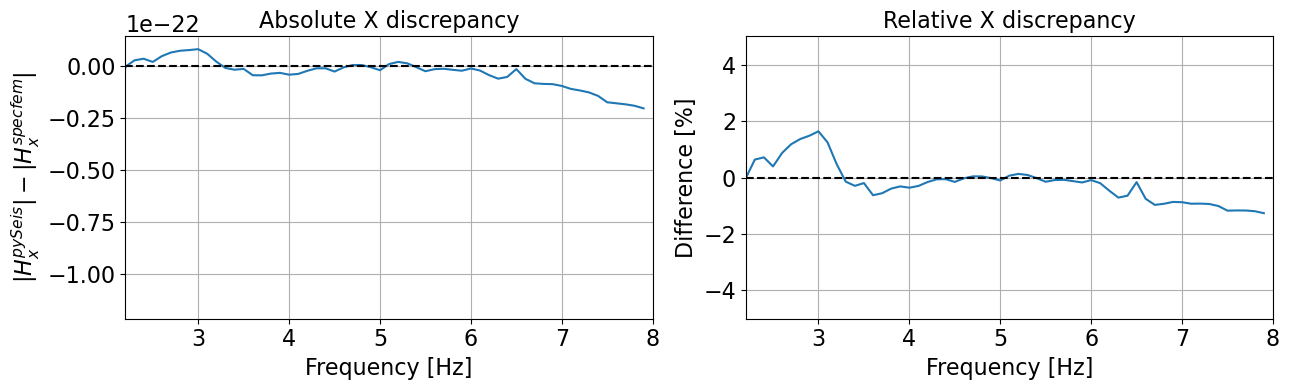

In [31]:
# X component, note Y component is symmetrically close to 0
specX_interp = np.interp(freqOut[selPy],freqSpec[selSpec],np.abs(HSpecBulk[selSpec, 0]))
pyX = np.abs(deconVolNN[selPy, 0, 0])
diffX = pyX - specX_interp
fig, ax = plt.subplots(1, 2,figsize=(13, 4))

ax[0].plot(freqOut[selPy],diffX)
ax[0].axhline(0.0,color="k",linestyle="--")
ax[0].set_xlim(2.2,8)
ax[0].set_xlabel("Frequency [Hz]")
ax[0].set_ylabel(r"$|H_x^{pySeis}|-|H_x^{specfem}|$")
ax[0].set_title("Absolute X discrepancy")
ax[0].grid()

ax[1].plot(freqOut[selPy],diffX / pyX * 100.0)
ax[1].axhline(0.0,color="k",linestyle="--")

ax[1].set_xlabel("Frequency [Hz]")
ax[1].set_ylabel("Difference [%]")
ax[1].set_title("Relative X discrepancy")
ax[1].grid()
ax[1].set_ylim(-5,5)
ax[1].set_xlim(2.2,8)

plt.tight_layout()
plt.show()